### FIM notes:

- train both spm and psm (give a percentage to each one)
- <EOT> is used for end of 

### Expand embedding table for new tokens

In [1]:
import torch
import torch.nn as nn

from unakin.llm.models.llama import LlamaTransformer

model = LlamaTransformer.from_json_file(path_or_json={
  "base": "code-llama-13b-instruct"
})

print("Before adding new embeddings:")
print(model.tok_embeddings.weight.shape)

old_emb_weight = model.tok_embeddings.weight

# # add new embeddings
# new_embeddings = nn.Embedding(1, 5120)

# # concatenate the new embeddings to the existing ones
# model.tok_embeddings.weight = nn.Parameter(torch.cat([model.tok_embeddings.weight, new_embeddings.weight], dim=0))

# print("After adding new embeddings:")
# print(model.tok_embeddings.weight.shape)

/mnt/raid0/llamas/llama_base/code-llama-13b-instruct.pth code-llama-13b-instruct
/mnt/raid0/llamas/llama_base/code-llama-13b-instruct.pth
Allocated virtual model in 0.023026466369628906s
Loaded virtual model in 0.0064220428466796875s
Before adding new embeddings:
torch.Size([32016, 5120])


In [2]:
print(model)

Transformer(
  (tok_embeddings): Embedding(32016, 5120)
  (layers): ModuleList(
    (0-39): 40 x TransformerBlock(
      (attention): Attention(
        (wq): Linear(in_features=5120, out_features=5120, bias=False)
        (wk): Linear(in_features=5120, out_features=5120, bias=False)
        (wv): Linear(in_features=5120, out_features=5120, bias=False)
        (wo): Linear(in_features=5120, out_features=5120, bias=False)
      )
      (feed_forward): FeedForward(
        (w1): Linear(in_features=5120, out_features=13824, bias=False)
        (w2): Linear(in_features=13824, out_features=5120, bias=False)
        (w3): Linear(in_features=5120, out_features=13824, bias=False)
      )
      (attention_norm): RMSNorm(5120)
      (ffn_norm): RMSNorm(5120)
    )
  )
  (norm): RMSNorm(5120)
  (output): Linear(in_features=5120, out_features=32016, bias=False)
)


In [6]:
old_emb_weight.shape

# mean and std on 0th dimension
mean = old_emb_weight.mean(dim=0)
std = old_emb_weight.std(dim=0)

print(mean.shape)
print(std.shape)

torch.Size([5120])
torch.Size([5120])


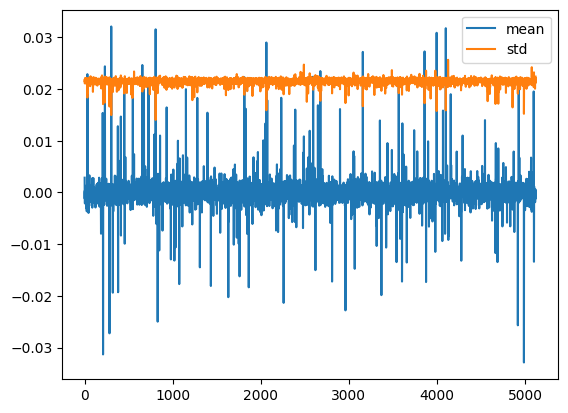

In [7]:
# plot the mean and std
import matplotlib.pyplot as plt
import numpy as np

plt.plot(mean.detach().numpy(), label='mean')
plt.plot(std.detach().numpy(), label='std')
plt.legend()
plt.show()


torch.Size([32016, 5120])
torch.Size([32016])
torch.Size([32016])


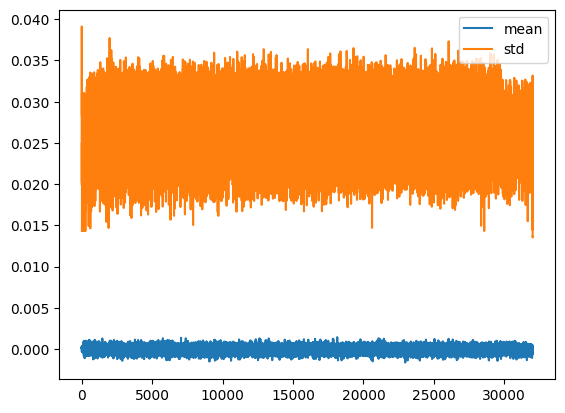

In [14]:
# the same with the output linear
out_linear = model.output
print(out_linear.weight.shape)

mean = out_linear.weight.mean(dim=1)
std = out_linear.weight.std(dim=1)

print(mean.shape)
print(std.shape)

# plot the mean and std
plt.plot(mean.detach().numpy(), label='mean')
plt.plot(std.detach().numpy(), label='std')
plt.legend()
plt.show()


In [15]:
mean = mean.mean()
std = std.mean()

In [16]:
mean, std

(tensor(-7.1168e-05, dtype=torch.float16, grad_fn=<MeanBackward0>),
 tensor(0.0266, dtype=torch.float16, grad_fn=<MeanBackward0>))

In [2]:
print(model)

Transformer(
  (tok_embeddings): Embedding(32016, 5120)
  (layers): ModuleList(
    (0-39): 40 x TransformerBlock(
      (attention): Attention(
        (wq): Linear(in_features=5120, out_features=5120, bias=False)
        (wk): Linear(in_features=5120, out_features=5120, bias=False)
        (wv): Linear(in_features=5120, out_features=5120, bias=False)
        (wo): Linear(in_features=5120, out_features=5120, bias=False)
      )
      (feed_forward): FeedForward(
        (w1): Linear(in_features=5120, out_features=13824, bias=False)
        (w2): Linear(in_features=13824, out_features=5120, bias=False)
        (w3): Linear(in_features=5120, out_features=13824, bias=False)
      )
      (attention_norm): RMSNorm(5120)
      (ffn_norm): RMSNorm(5120)
    )
  )
  (norm): RMSNorm(5120)
  (output): Linear(in_features=5120, out_features=32016, bias=False)
)


In [3]:
# also add the new embedding to the output layer

output_weights = model.output.weight

new_embeddings = nn.Linear(5120, 1)

after_weights = torch.cat([output_weights, new_embeddings.weight], dim=0)

print("After adding new embeddings to the output layer:")
print(after_weights.shape)

After adding new embeddings to the output layer:
torch.Size([32017, 5120])


### How to add new tokens to a pretrained sentencepiece model

In [1]:
import sentencepiece as smp
import sentencepiece.sentencepiece_model_pb2 as model_pb

mp = model_pb.ModelProto()

model_file = '/mnt/raid0/llamas/codellama/CodeLlama-13b-Instruct/tokenizer.model'
symbols = ['[REV]']

mp.ParseFromString(open(model_file, 'rb').read())

print(f'Original model pieces: {len(mp.pieces)}')

for i, sym in enumerate(symbols, 1):
    new_sym = mp.SentencePiece()
    new_sym.piece = sym 
    new_sym.score = 0.0             # default score for USER_DEFINED
    new_sym.type = 4                # type value for USER_DEFINED
    mp.pieces.append(new_sym)       # insert at the end

print(f'New model pieces: {len(mp.pieces)}')

outfile = '/mnt/raid0/llamas/codellama/CodeLlama-13b-Instruct/tokenizer_with_rev.model'

with open(outfile, 'wb') as f:
    f.write(mp.SerializeToString())

Original model pieces: 32016
New model pieces: 32017


In [3]:

llama_tokenizer = smp.SentencePieceProcessor(model_file=outfile)
llama_og = smp.SentencePieceProcessor(model_file=model_file)

print(f'New model pieces: {llama_tokenizer.get_piece_size()}')

enc_ap_text = llama_tokenizer.encode_as_pieces("My name is John [REV] <PRE> <EOT> ")
print(enc_ap_text)
enc_text = llama_tokenizer.encode("My name is John [REV] <SUF>")
print(enc_text)

print(f'Original model pieces: {llama_og.get_piece_size()}')

enc_og = llama_og.encode_as_pieces("My name is John [REV]")
print(enc_og)
enc_og = llama_og.encode("My name is John [REV]")
print(enc_og)

# print eos piece
print(llama_tokenizer.PieceToId('[REV]x'))


New model pieces: 32017
['▁My', '▁name', '▁is', '▁John', '▁', '[REV]', '▁<PRE>', '▁<EOT>', '▁']
[1619, 1024, 338, 2259, 29871, 32016, 32008]
Original model pieces: 32016
['▁My', '▁name', '▁is', '▁John', '▁[', 'RE', 'V', ']']
[1619, 1024, 338, 2259, 518, 1525, 29963, 29962]
0


In [13]:
# pad token
print(llama_tokenizer.pad_id())
print(llama_og.pad_id())

-1
-1


In [ ]:
# print all control symbols
print('Control symbols:')
for i in range(llama_tokenizer.get_piece_size()):
    piece = llama_tokenizer.id_to_piece(i)
    if piece.startswith('<'):
        print(f'{i}: {piece}')

In [ ]:
import sentencepiece as spm

llama_spm = spm.SentencePieceProcessor(model_file='/mnt/raid0/llamas/codellama/CodeLlama-13b-Instruct/tokenizer.model')


enc_ap_text = llama_spm.encode_as_pieces("My name is John [REV]")
print(enc_ap_text)
enc_text = llama_spm.encode("My name is John [REV]")
print(enc_text)


In [ ]:
print(llama_spm.

In [ ]:
from unakin.llm.oss.llama.llama.tokenizer import Tokenizer

llama_tokenizer = Tokenizer(model_path="/mnt/raid0/llamas/codellama/CodeLlama-13b-Instruct/tokenizer.model")

In [ ]:
# open tokenizer.model to see what the model is

with open("/mnt/raid0/llamas/codellama/CodeLlama-13b-Instruct/tokenizer.model", "rb") as f:
    # print(f.read())
    # transform to utf-8
    print(f.read())


In [ ]:
# add [REV] to the vocabulary
llama_tokenizer.sp_model.addSpecialTokens(["[REV]"])

In [ ]:
enc_ap_text = llama_tokenizer.sp_model.encode_as_pieces("My name is John [REV]")
print(enc_ap_text)
enc_text = llama_tokenizer.sp_model.encode("My name is John [REV]")
print(enc_text)
# # decode each token
# for token in enc_text:
#     print(llama_tokenizer.sp_model.id_to_piece(token), end=" ")

In [ ]:
import random
from typing import List

def reverse_sample(
    sample: List[int],
    rev_token: int,
    max_len: int,
):
  len_sample = len(sample)
  split_sample = []
  curr_sum = 0
  for _ in range(len_sample):
    next_seg_size = random.randint(1, max_len)
    split_sample.append(sample[curr_sum:curr_sum + next_seg_size])
    if curr_sum + next_seg_size >= len_sample:
      break
    curr_sum += next_seg_size

  print(split_sample)

  rev_split_sample = []
  for curr_seg in split_sample[::-1]:
    rev_split_sample.append([rev_token])
    rev_split_sample.append(curr_seg)

  # flatten
  rev_split_sample = [item for sublist in rev_split_sample for item in sublist]
  return rev_split_sample


reverse_token = -1
rnd_sample = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

print(reverse_sample(rnd_sample, reverse_token, 5))


In [5]:
import random
from typing import List, Tuple

def fim_sample(
    sample: List[int],
    suffix_lims: Tuple[int, int],
    prefix_lims: Tuple[int, int],
    pre_token: int,
    suf_token: int,
    mid_token: int,
    eot_token: int,
):
  # according to: https://arxiv.org/pdf/2207.14255.pdf
  suffix_percentage = random.uniform(suffix_lims[0], suffix_lims[1])
  prefix_percentage = random.uniform(prefix_lims[0], prefix_lims[1])

  suffix_len = int(len(sample) * suffix_percentage)
  prefix_len = int(len(sample) * prefix_percentage)

  pre_sample = sample[:prefix_len]
  suf_sample = sample[-suffix_len:]
  mid_sample = sample[prefix_len:-suffix_len]

  # psm or spm with equal probability
  if random.random() < 0.5:
    # psm
    return [pre_token] + pre_sample + [suf_token] + suf_sample + [mid_token] + mid_sample + [eot_token]
  else:
    return [suf_token] + suf_sample + [pre_token] + pre_sample + [mid_token] + mid_sample + [eot_token]


rnd_sample = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

print(fim_sample(rnd_sample, [.1, .3], [.1, .3], -2, -3, -4, -5))

[-3, 13, 14, 15, -2, 1, 2, 3, -4, 4, 5, 6, 7, 8, 9, 10, 11, 12, -5]


In [8]:
  # prob:
  #   original: 0.3
  #   fim:      0.3
  #   rev:      0.3

prob_dict = {
  "original": 0.3,
  "fim": 0.3,
  "rev": 0.3
}

prep_type = random.choices(list(prob_dict.keys()), weights=list(prob_dict.values()), k=1)[0]
prep_type

'rev'

In [7]:
from typing import List

dialogs = [[
        {"role": "system", "content": "This is a system message."},
        {"role": "user", "content": "Hello!"},
        {"role": "assistant", "content": "How can I help you today? 1 "},
        {"role": "user", "content": "I need help with my computer. 1 "},
        {"role": "assistant", "content": "How can I help you today? 2 "},
        {"role": "user", "content": "I need help with my computer. 2 "}, 
]]


B_SYS = " [SYS] "
E_SYS = " [/SYS] "
B_INST = " [INST] "
E_INST = " [/INST] "

dialog_tokens = []
for dialog in dialogs:
    if dialog[0]["role"] == "system":
        dialog = [  # type: ignore
            {
                "role": dialog[1]["role"],
                "content": B_SYS
                + dialog[0]["content"]
                + E_SYS
                + dialog[1]["content"],
            }
        ] + dialog[2:]
    assert all([msg["role"] == "user" for msg in dialog[::2]]) and all(
        [msg["role"] == "assistant" for msg in dialog[1::2]]
    ), (
        "model only supports 'system', 'user' and 'assistant' roles, "
        "starting with 'system', then 'user' and alternating (u/a/u/a/u...)"
    )
    # print(dialog)
    dialog_tokens =\
        [
            f"{B_INST} {prompt['content'].strip()} {E_INST} {answer['content'].strip()} "
            for prompt, answer in zip(
                dialog[::2],
                dialog[1::2],
            )
        ]
    print(dialog_tokens)
    # dialog_tokens += f"{B_INST} {dialog[-1]['content'].strip()} {E_INST}"
    

[' [INST]  [SYS] This is a system message. [/SYS] Hello!  [/INST]  How can I help you today? 1 ', ' [INST]  I need help with my computer. 1  [/INST]  How can I help you today? 2 ']


In [ ]:
dialog_tokens

In [ ]:
import torch

model = torch.nn.Linear(1, 1)

total_steps = 100
warmup_ratio = 0.1

warmup_steps = int(total_steps * warmup_ratio)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
lr_scheduler_1 = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=warmup_steps)
lr_scheduler_2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps - warmup_steps, eta_min=1e-4)
lr_scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [lr_scheduler_1, lr_scheduler_2], [warmup_steps])


In [ ]:
# plot the learning rate schedule
import matplotlib.pyplot as plt

lrs = []
for i in range(100):
    lr_scheduler.step()
    lrs.append(optimizer.param_groups[0]["lr"])

plt.plot(lrs)

In [ ]:
lrs[0]

In [ ]:
lrs[-1]